The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


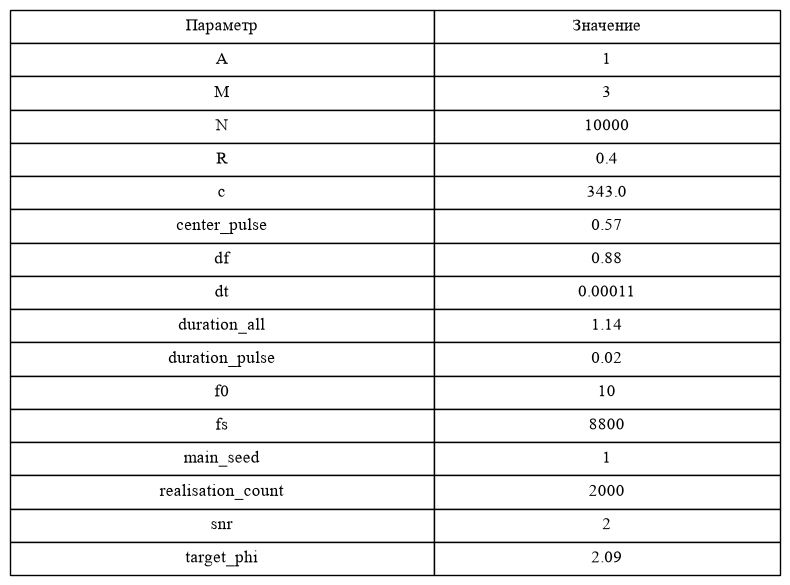

In [ ]:
"""В данном модуле исследуется зависимость центральной частоты гармонического
сигнала от статистических характеристик. Сравниваются точная и приближённая модели.
Определяется область частот, в которой применима приближённая
модель"""

import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
%load_ext autoreload
%autoreload 2

import numpy as np
import time
from src.experiments import (stat_vs_params, calculate_variance)
from src.functions import (calculate_bartlett_values, get_sin_signal, get_impulse_signal, calculate_stiring_matrix, calculate_complex_stiring_matrix, calculate_full_bartlett_values,)
from src.configs.config import init_rng, restart_rng
import src.configs.config as cfg
import src.configs.comon as comon
from src.plotting import plot_variance_vs_param, plot_mean_vs_param, create_config_table
import os
origin_config = init_rng()
sin_signal = get_sin_signal
path = "attachment/images/report"
os.makedirs(path,exist_ok=True)
create_config_table(origin_config)

In [ ]:
conf1 = restart_rng(origin_config)
conf2 = restart_rng(origin_config)
start_time = time.perf_counter()
    
        
end_time = time.perf_counter()
delta_time = end_time - start_time

mean_bartlett_vs_f = stat_vs_params(config_params=conf1,
                                   energy_func=calculate_bartlett_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False
                                   )

mean_bartlett_vs_f_complex = stat_vs_params(config_params = conf2,
                                   energy_func = calculate_full_bartlett_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_complex_stiring_matrix,
                                   stat_func = np.mean,
                                   is_CRN = False)

delta_var = np.abs(np.array(mean_bartlett_vs_f_complex) - np.array(mean_bartlett_vs_f))
end_time = time.perf_counter()

delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel=' Частота сигнала $f_{0}$, Гц', ylabel='$\\mathbb{E}[\\varepsilon]$, $град$'>)

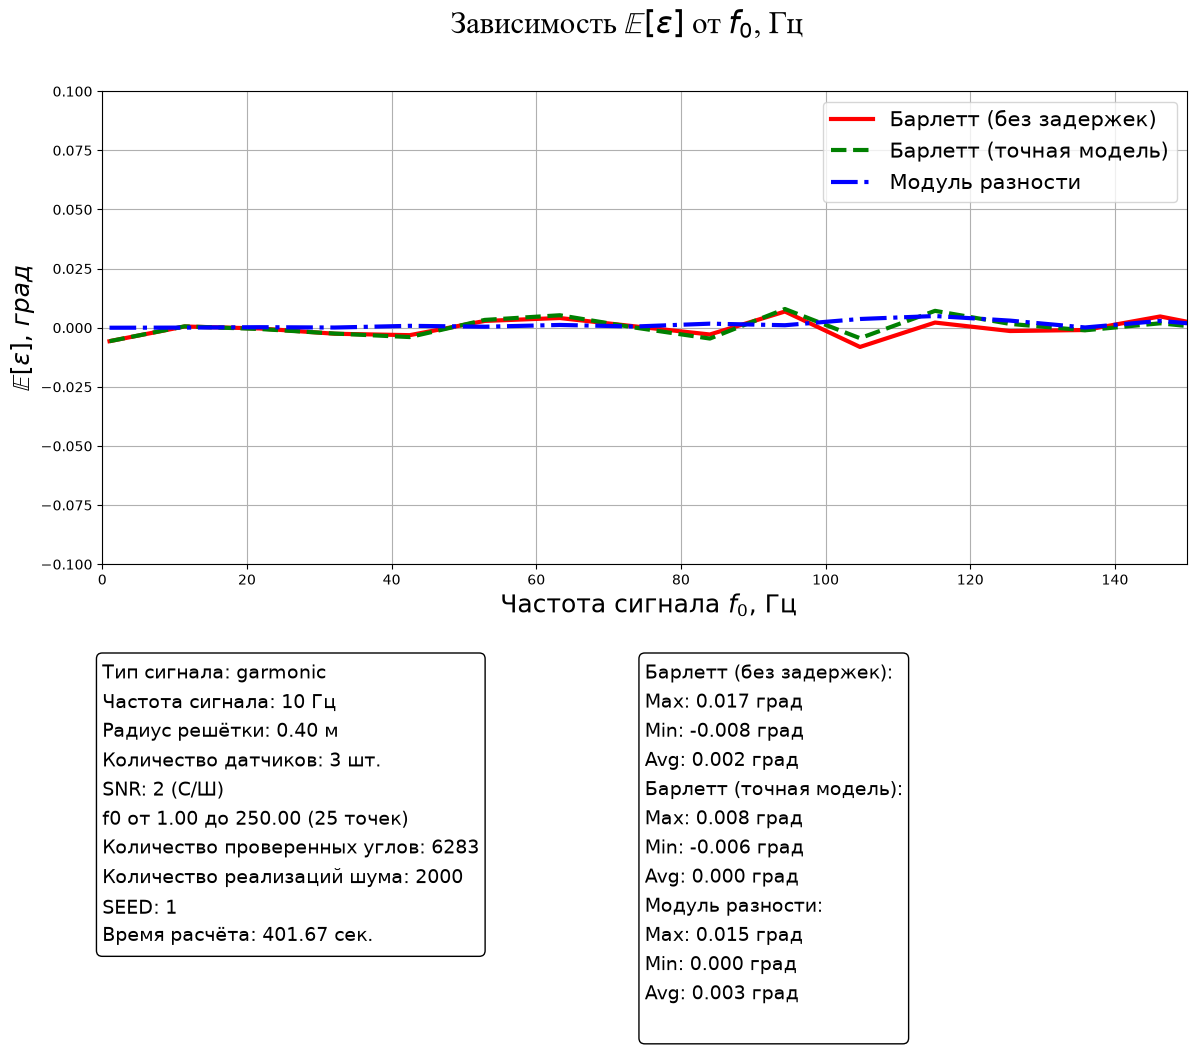

In [ ]:
plot_mean_vs_param(dict_values = {"Bartlett (no delays)": mean_bartlett_vs_f,
                                      "Bartlett (exact model)": mean_bartlett_vs_f_complex,
                                      "Absolute difference": delta_var},

                       config_params = origin_config.copy(),
                       parametr_values = cfg.FREQ_VALUES,
                       parametr_name = "f0",
                       delta_time = delta_time,
                       ylim = (-0.1*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,150),
                       type_signal = "garmonic"
                       )

In [ ]:
conf1 = restart_rng(origin_config)
conf2 = restart_rng(origin_config)
start_time = time.perf_counter()
    
        
end_time = time.perf_counter()
delta_time = end_time - start_time

var_bartlett_vs_f = stat_vs_params(config_params=conf1,
                                   energy_func=calculate_bartlett_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_stiring_matrix,
                                   stat_func = calculate_variance,
                                   is_CRN = False
                                   )

var_bartlett_vs_f_complex = stat_vs_params(config_params = conf2,
                                   energy_func = calculate_full_bartlett_values,
                                   signal_func = sin_signal,
                                   parametr_name = "f0",
                                   parametr_values = cfg.FREQ_VALUES,
                                   stiring_func = calculate_complex_stiring_matrix,
                                   stat_func = calculate_variance,
                                   is_CRN = False)

delta_var = np.abs(np.array(var_bartlett_vs_f_complex) - np.array(var_bartlett_vs_f))
end_time = time.perf_counter()

delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel=' Частота сигнала $f_{0}$, Гц', ylabel='$s_{\\varepsilon}^{2}$, $град^2$'>)

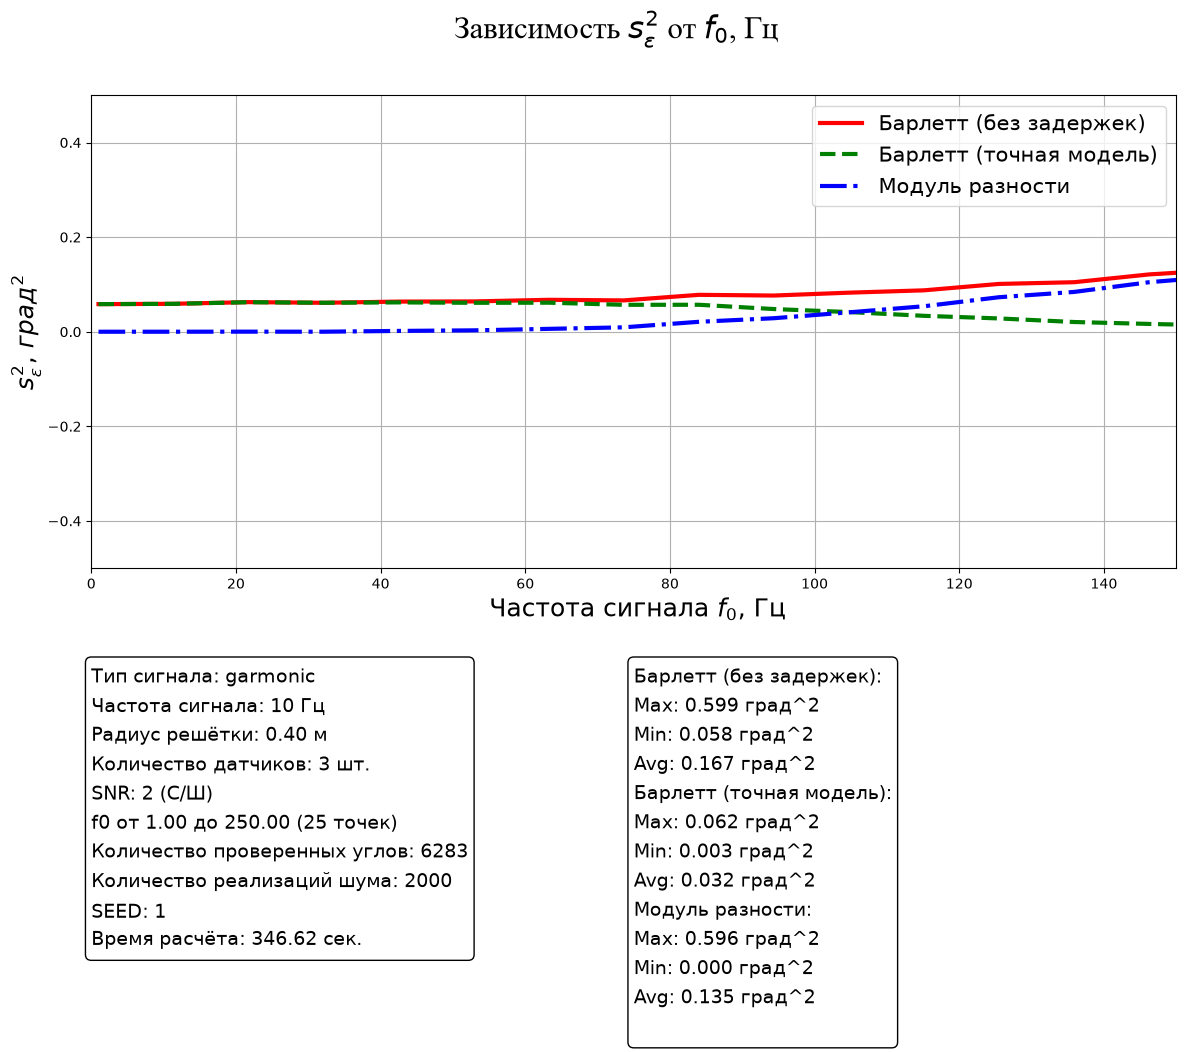

In [ ]:
plot_variance_vs_param(dict_values = {"Bartlett (no delays)": var_bartlett_vs_f,
                                      "Bartlett (exact model)": var_bartlett_vs_f_complex,
                                      "Absolute difference": delta_var},

                       config_params = origin_config.copy(),
                       parametr_values = cfg.FREQ_VALUES,
                       parametr_name = "f0",
                       delta_time = delta_time,
                       ylim = (-0.5*comon.CONST_RADIAN, 0.5*comon.CONST_RADIAN),
                       xlim = (0, 150),
                       type_signal = "garmonic"
                       )